In [1]:
using Pkg
Pkg.activate("./..")

using CairoMakie
using SURD

  Activating project at `~/Desktop/github/SURD.jl`


## Mediator variable

The first example corresponds to the system $Q_3 \rightarrow Q_2 \rightarrow Q_1$, where $Q_3$ acts on $Q_1$ through the mediator variable $Q_2$. The equations governing the system are as follows:
\begin{align*}
Q_1(n+1) &= \sin[Q_2(n)] + 0.001W_1(n) \\
Q_2(n+1) &= \cos[Q_3(n)] + 0.01W_2(n) \\
Q_3(n+1) &= 0.9Q_3(n) + 0.1W_3(n),
\end{align*}
where $W_i$ represents stochastic forcing on the variable and follows a Gaussian distribution with a mean of zero and a standard deviation of one. The system is initially set to $Q_1(1) = Q_2(1) = Q_3(1) = 0$.

In [2]:
# Example data
Nt = 10_000
Q1 = zeros(Nt)
Q2 = zeros(Nt)
Q3 = zeros(Nt)

# Initialize the time series with some random values
Q1[1] = 0.0
Q2[1] = 0.0
Q3[1] = 0.0

# Generate synthetic time series data
for i in 2:Nt
    Q1[i] = sin(Q2[i-1]) + 0.001 * randn()
    Q2[i] = cos(Q3[i-1]) + 0.01 * randn()
    Q3[i] = 0.5 * Q3[i-1] + 0.1 * randn()
end

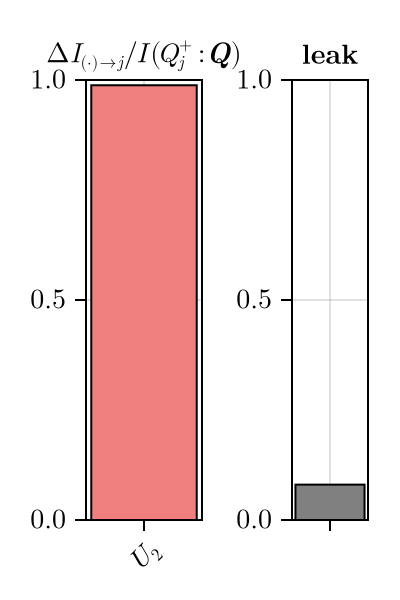

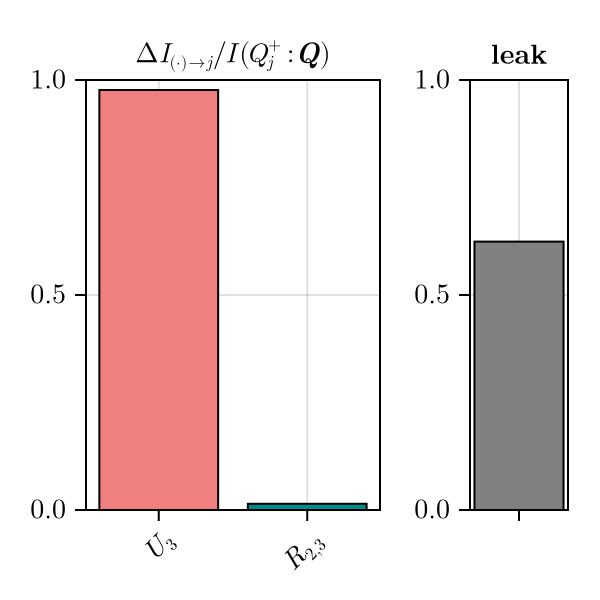

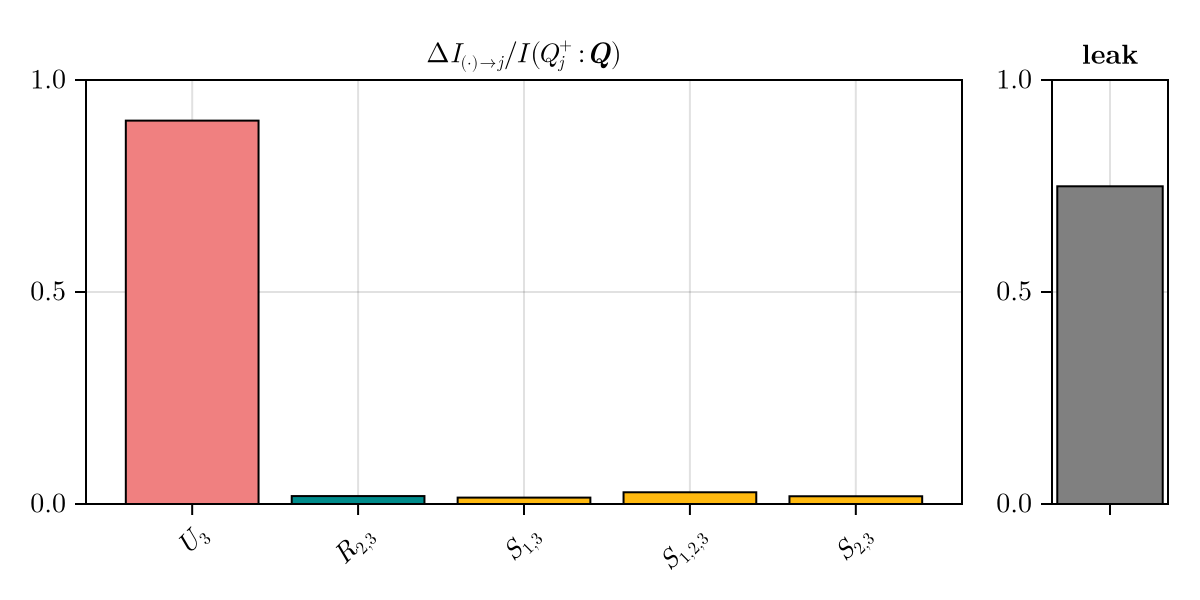

CairoMakie.Screen{IMAGE}


In [3]:
result1 = surd(Q1[2:end], (Q1[1:end-1], Q2[1:end-1], Q3[1:end-1]), SURD.kNN())
result2 = surd(Q2[2:end], (Q1[1:end-1], Q2[1:end-1], Q3[1:end-1]), SURD.kNN())
result3 = surd(Q3[2:end], (Q1[1:end-1], Q2[1:end-1], Q3[1:end-1]), SURD.kNN())

display(surd_plot(result1))
display(surd_plot(result2))
display(surd_plot(result3))

## Confounder variable

The second example considered corresponds to a system where $Q_3$ is a confounder variable to $Q_1$ and $Q_2$, i.e., $Q_3 \rightarrow Q_1$ and $Q_3 \rightarrow Q_2$.

\begin{align*}
    Q_1(n+1) &= \sin[Q_1(n) + Q_3(n)] + 0.01W_1(n)\\
    Q_2(n+1) &= \cos[Q_2(n) - Q_3(n)] + 0.01W_2(n) \\
    Q_3(n+1) &= 0.5Q_3(n) + 0.1W_3(n)
\end{align*}

In [4]:
# Example data
Nt = 10_000
Q1 = zeros(Nt)
Q2 = zeros(Nt)
Q3 = zeros(Nt)

# Initialize the time series with some random values
Q1[1] = 0.0
Q2[1] = 0.0
Q3[1] = 0.0

# Generate synthetic time series data
for i in 2:Nt
    Q1[i] = sin(Q1[i-1] + Q3[i-1]) + 0.01 * randn()
    Q2[i] = cos(Q2[i-1] - Q3[i-1]) + 0.01 * randn()
    Q3[i] = 0.5 * Q3[i-1] + 0.1 * randn()
end

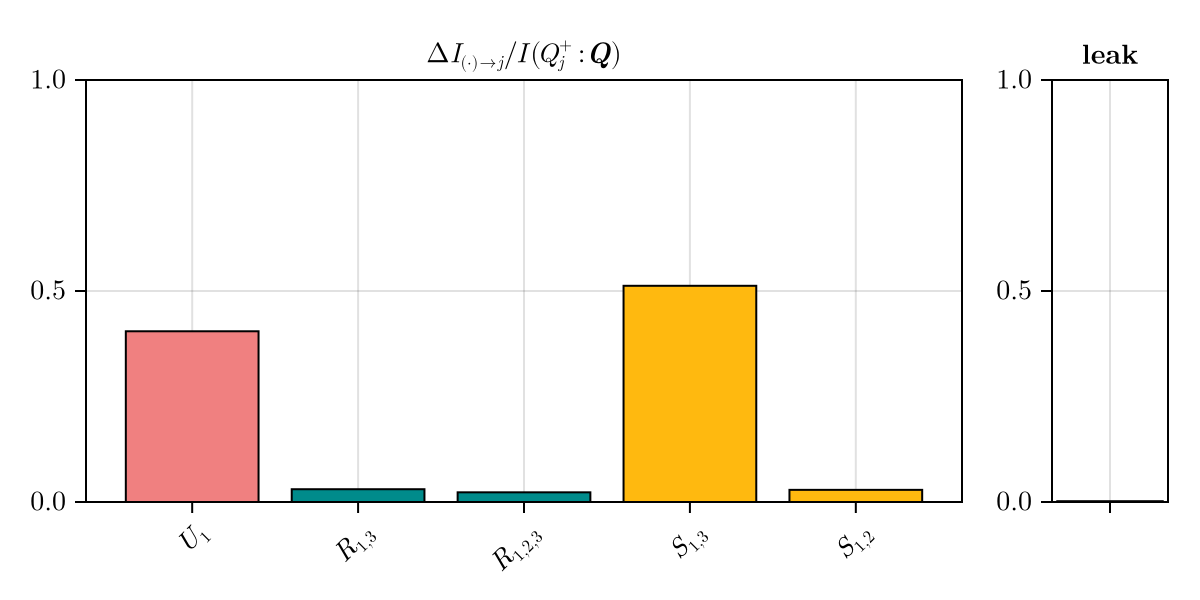

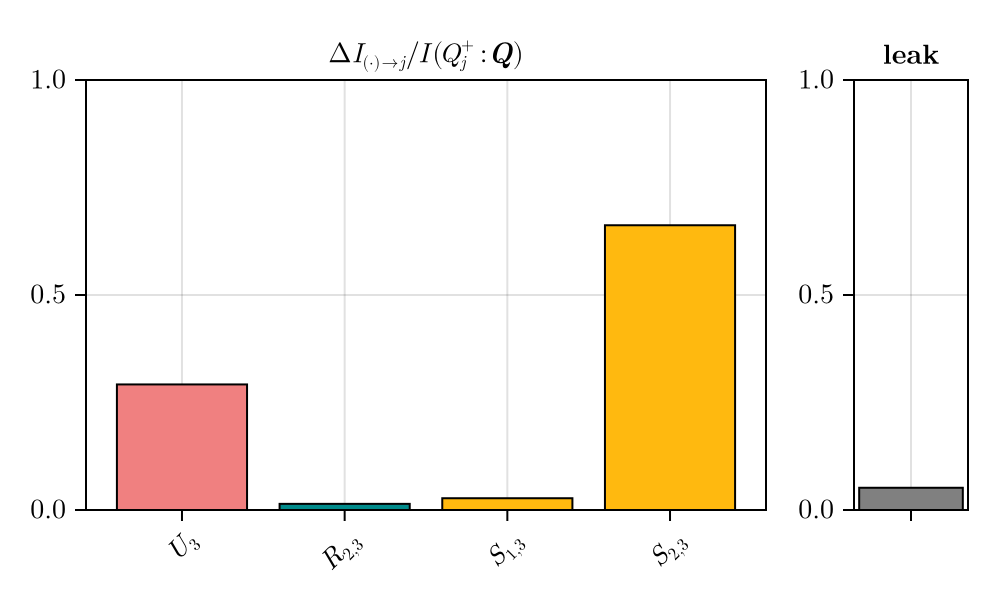

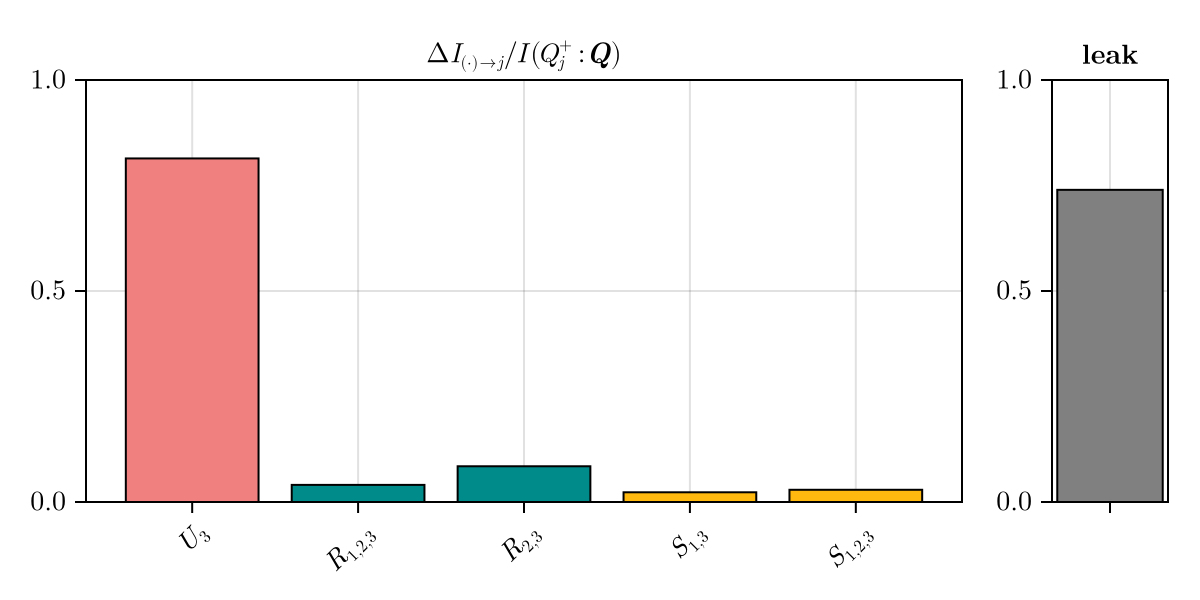

CairoMakie.Screen{IMAGE}


In [5]:
result1 = surd(Q1[2:end], (Q1[1:end-1], Q2[1:end-1], Q3[1:end-1]), SURD.kNN())
result2 = surd(Q2[2:end], (Q1[1:end-1], Q2[1:end-1], Q3[1:end-1]), SURD.kNN())
result3 = surd(Q3[2:end], (Q1[1:end-1], Q2[1:end-1], Q3[1:end-1]), SURD.kNN())

display(surd_plot(result1))
display(surd_plot(result2))
display(surd_plot(result3))

## Synergistic collider

The third example considered here corresponds to the system $[Q_2,Q_3] \rightarrow Q_1$, where $Q_2$ and $Q_3$ work together to influence $Q_1$. In reality, variables $Q_2$ and $Q_3$ behave as a single random variable that drives $Q_1$.

\begin{align*}
    Q_1(n+1) &= \sin[Q_2(n)Q_3(n)] + 0.001W_1(n) \\
    Q_2(n+1) &= 0.5Q_2(n) + 0.1W_2(n) \\
    Q_3(n+1) &= 0.5Q_3(n) + 0.1W_3(n)
\end{align*}

In [6]:
# Example data
Nt = 10_000
Q1 = zeros(Nt)
Q2 = zeros(Nt)
Q3 = zeros(Nt)

# Initialize the time series with some random values
Q1[1] = 0.0
Q2[1] = 0.0
Q3[1] = 0.0

# Generate synthetic time series data
for i in 2:Nt
    Q1[i] = sin(Q2[i-1] * Q3[i-1]) + 0.001 * randn()
    Q2[i] = 0.5 * Q2[i-1] + 0.1 * randn()
    Q3[i] = 0.5 * Q3[i-1] + 0.1 * randn()
end

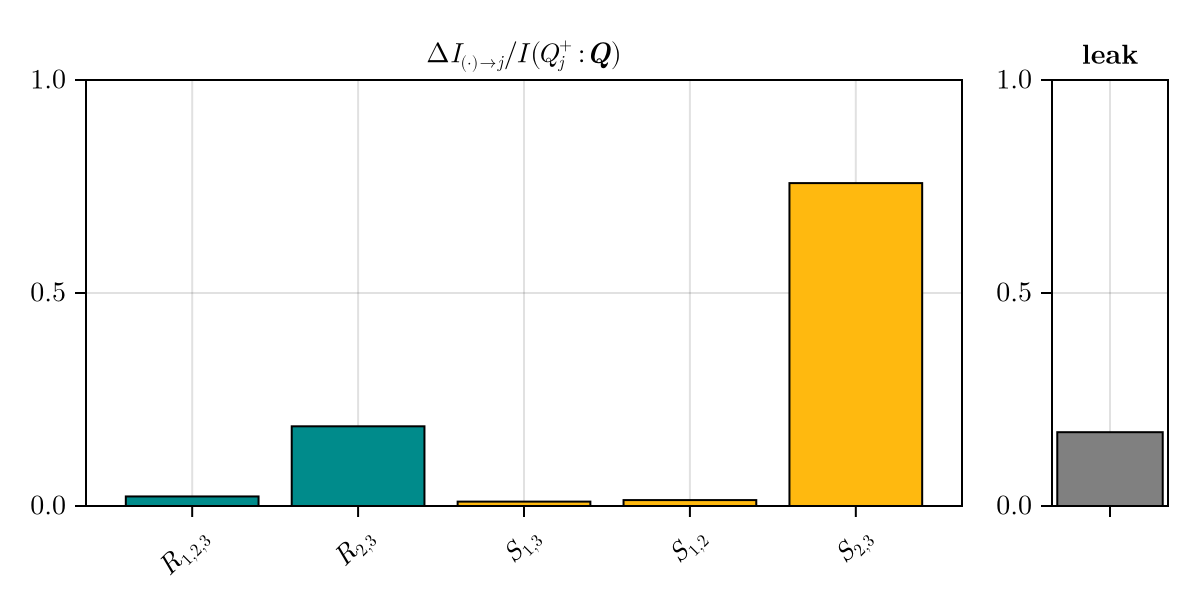

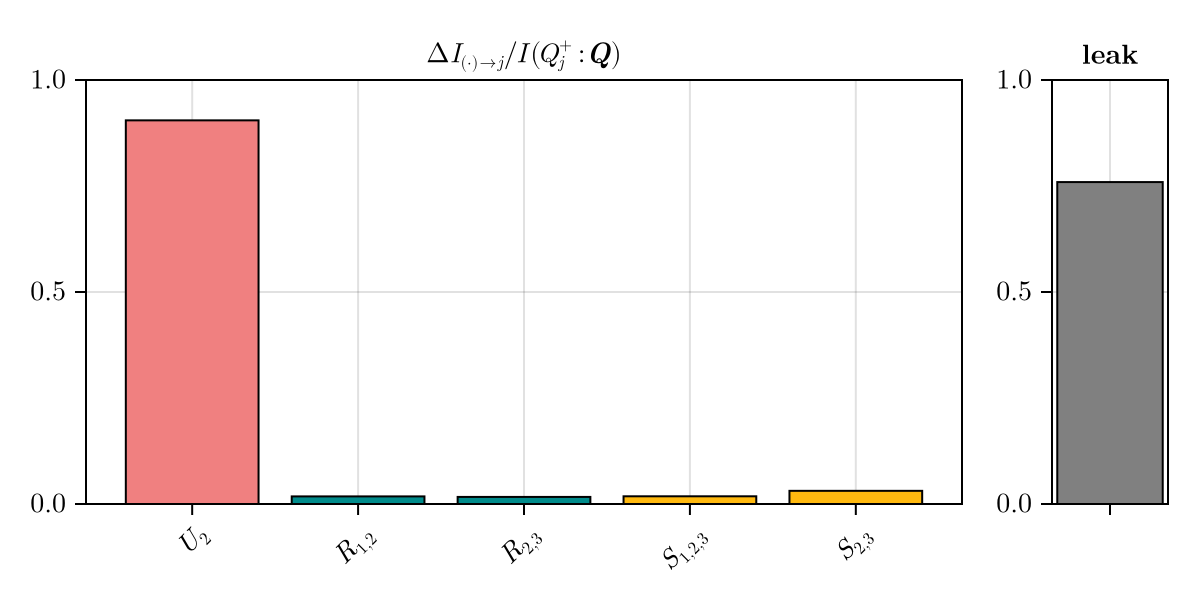

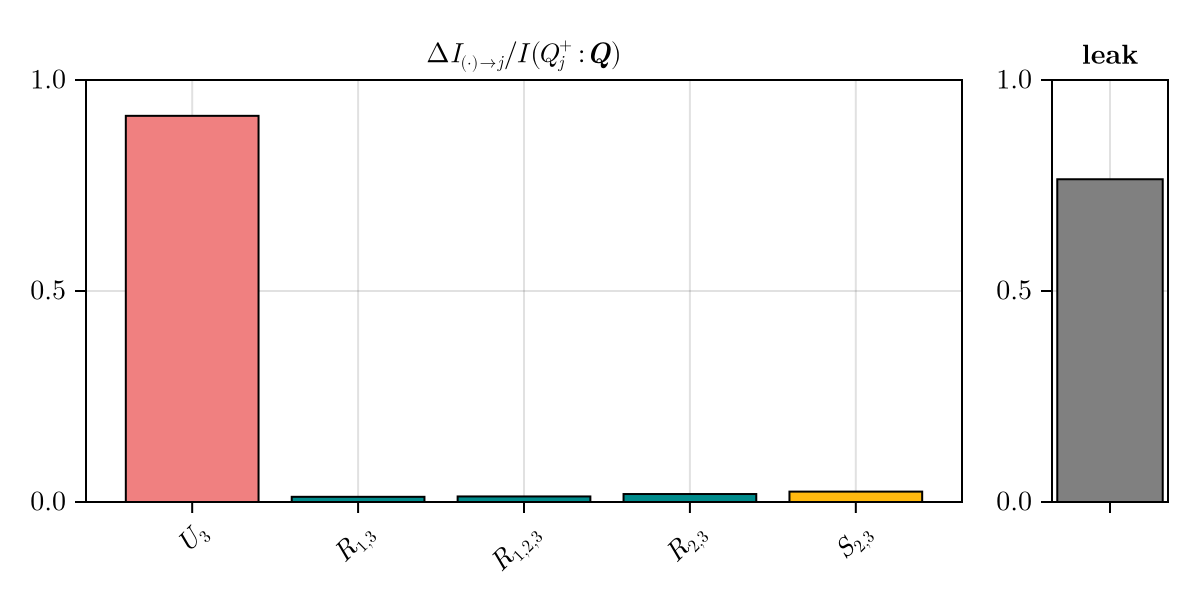

CairoMakie.Screen{IMAGE}


In [7]:
result1 = surd(Q1[2:end], (Q1[1:end-1], Q2[1:end-1], Q3[1:end-1]), SURD.kNN())
result2 = surd(Q2[2:end], (Q1[1:end-1], Q2[1:end-1], Q3[1:end-1]), SURD.kNN())
result3 = surd(Q3[2:end], (Q1[1:end-1], Q2[1:end-1], Q3[1:end-1]), SURD.kNN())

display(surd_plot(result1))
display(surd_plot(result2))
display(surd_plot(result3))

## Redundant collider

The last example represents the system $Q_2 \equiv Q_3 \rightarrow Q_1$, where $Q_3$ is the same as $Q_2$. In this situation, both $Q_2$ and $Q_3$ provide the same information about their influence on the future of $Q_1$.

\begin{align*}
    Q_1(n+1) &=  0.3Q_1(n) + \sin[Q_2(n)Q_3(n)] + 0.001 W_1(n)\\
    Q_2(n+1) &= 0.5 Q_2(n) + 0.1W_2(n) \\
    Q_3(n+1) &\equiv Q_2(n+1)
\end{align*}

In [8]:
# Example data
Nt = 10_000
Q1 = zeros(Nt)
Q2 = zeros(Nt)
Q3 = zeros(Nt)

# Initialize the time series with some random values
Q1[1] = 0.0
Q2[1] = 0.0
Q3[1] = 0.0

# Generate synthetic time series data
for i in 2:Nt
    Q1[i] = 0.3 * Q1[i-1] + sin(Q2[i-1] * Q3[i-1]) + 0.001 * randn()
    Q2[i] = 0.5 * Q2[i-1] + 0.1 * randn()
    Q3[i] = Q2[i]
end

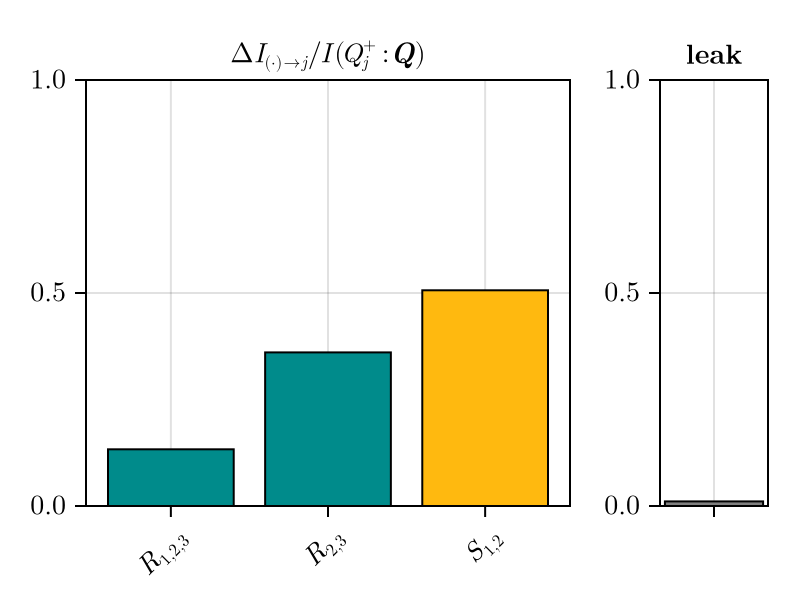

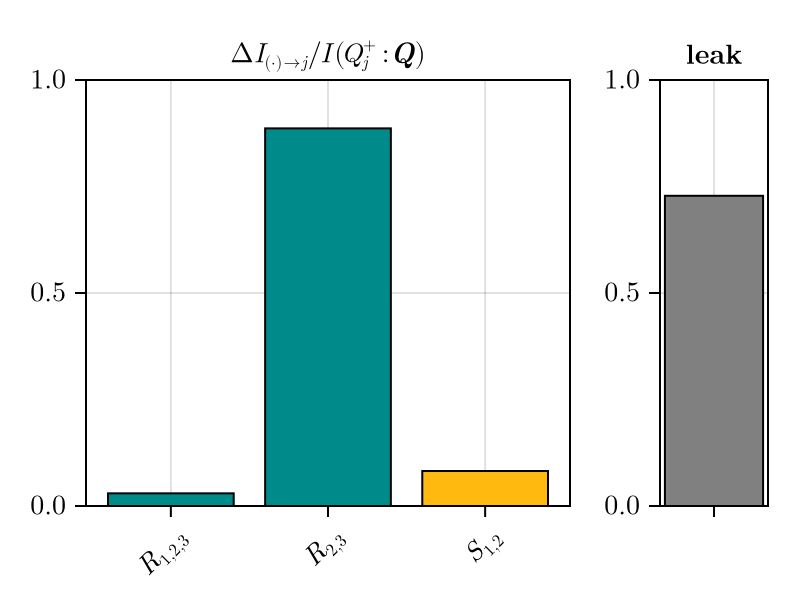

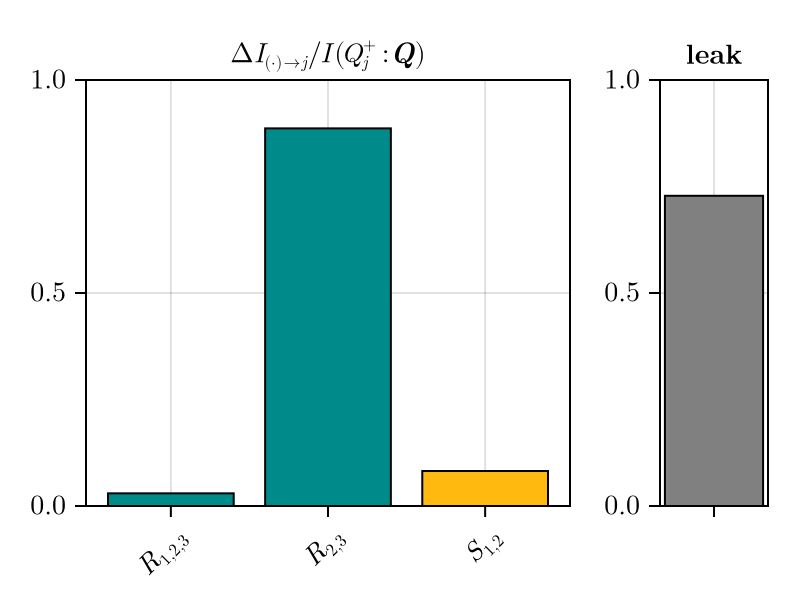

CairoMakie.Screen{IMAGE}


In [9]:
result1 = surd(Q1[2:end], (Q1[1:end-1], Q2[1:end-1], Q3[1:end-1]), SURD.kNN())
result2 = surd(Q2[2:end], (Q1[1:end-1], Q2[1:end-1], Q3[1:end-1]), SURD.kNN())
result3 = surd(Q3[2:end], (Q1[1:end-1], Q2[1:end-1], Q3[1:end-1]), SURD.kNN())

display(surd_plot(result1))
display(surd_plot(result2))
display(surd_plot(result3))